# Bottle inspection with a PatchCore-inspired detector

**Revision notebook** · Run from top to bottom in your patchcore-m1 kernel. Read the question above each code cell, predict the result, then press **Shift + Enter**. Some cells define a function and finish silently. Saved images and measurements come from your original notebook run.

Follow one bottle through the project: photo → CNN feature grids → patch vectors → distances to good examples → score → decision and heatmap. This educational variant uses ResNet18, a sampled greedy coreset and a maximum nearest-neighbour distance.

## Part 1 · Set up and inspect the data

### 01 · Check PyTorch

Find the PyTorch version your notebook is actually using.

**Read the code.** Importing torch checks that this kernel can load it.

**Check yourself.** Your recorded version was 2.15.0.

In [ ]:
import torch
print(torch.__version__)

2.15.0


### 02 · Test the compute device

MPS lets PyTorch use your Mac GPU. CPU is the fallback.

**Read the code.** The tensor is created on the selected device and multiplied by two.

**Check yourself.** Which device produced 6.0?

In [ ]:
import torch

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
number = torch.tensor([3.0], device=device)
result = number * 2

print("Device:", result.device.type)
print("Answer:", result.item())

Device: mps
Answer: 6.0


### 03 · Locate the good training photos

The dataset separates normal examples, test photos, and defect masks. Only train/good belongs in the normal reference pool.

**Read the code.** Path joins build the folder name. glob collects filenames without loading their pixels.

**Check yourself.** Look for the expected folder and a nonzero count.

In [ ]:
from pathlib import Path

import torch
from PIL import Image
from IPython.display import display
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models.feature_extraction import create_feature_extractor
from torchvision.transforms import Compose, Resize, ToTensor, Normalize

roots = [Path.cwd(), *Path.cwd().parents, Path.home() / "PatchCore_Anomaly_Detection"]
project_root = next((p for p in roots if (p / "data/mvtec_anomaly_detection/bottle/train/good").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open the notebook inside the project containing data/mvtec_anomaly_detection/bottle/train/good.")
bottle_dir = project_root / "data" / "mvtec_anomaly_detection" / "bottle"
good_dir = bottle_dir / "train" / "good"

if not good_dir.is_dir():
    raise FileNotFoundError(f"Check this folder in Finder: {good_dir}")

photos = sorted(good_dir.glob("*.png"))
if not photos:
    raise FileNotFoundError(f"No PNG images found in {good_dir}")


print(good_dir, len(photos))

### 04 · Open one normal bottle

See what the detector will receive before converting it into numbers.

**Read the code.** RGB means red, green and blue. photos[0] picks the first sorted filename.

**Check yourself.** Can you trace the intact rim in the displayed photo?

Normal training photos found: 209


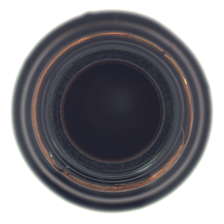

In [ ]:
with Image.open(photos[0]) as source:
    photo = source.convert("RGB")

print("Normal training photos found:", len(photos))
display(photo.resize((224, 224)))

## Part 2 · Turn one image into patch descriptions

### 05 · Prepare the input tensor

The pretrained CNN expects a consistent image size and color scale.

**Read the code.** Resize sets 224 × 224, Normalize adjusts each color channel, and unsqueeze adds the batch dimension.

**Check yourself.** Read (1, 3, 224, 224) as one image, three colors, height and width.

In [ ]:
preprocess = Compose([
    Resize((224, 224)),
    ToTensor(),
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
batch = preprocess(photo).unsqueeze(0)


print(tuple(batch.shape))

### 06 · Load the frozen feature extractor

A convolution applies a learned filter across nearby pixels. ResNet18 already has filters for useful visual patterns.

**Read the code.** create_feature_extractor requests layer2 and layer3. eval() sets inference behavior; the next cell disables gradient tracking.

**Check yourself.** This cell prepares the network. Its first run may download the pretrained weights.

In [ ]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = resnet18(weights=ResNet18_Weights.DEFAULT)
extractor = create_feature_extractor(
    model, return_nodes={"layer2": "layer2", "layer3": "layer3"}
).eval().to(device)

### 07 · Read two feature grids

A feature map records a filter response at many image positions.

**Read the code.** Passing batch through extractor returns both grids in a dictionary.

**Check yourself.** Which grid is finer? Layer 2 has 28 × 28 positions; layer 3 has 14 × 14.

In [ ]:
with torch.inference_mode():
    features = extractor(batch.to(device))

print("Input:", tuple(batch.shape))
for name, feature_map in features.items():
    print(name, tuple(feature_map.shape))

Input: (1, 3, 224, 224)
layer2 (1, 128, 28, 28)
layer3 (1, 256, 14, 14)


### 08 · Build one vector per location

An embedding is a list of numbers describing a region, such as part of the rim.

**Read the code.** interpolate aligns both grids. cat joins 128 and 256 channels. reshape gives one row per location.

**Check yourself.** The function definition finishes silently. For one photo it will return 784 rows, each with 384 values.

In [ ]:
import random
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw
from IPython.display import display

if not all(name in globals() for name in ("extractor", "preprocess", "device", "bottle_dir")):
    raise RuntimeError("Run the earlier ResNet18 feature-extraction cell first.")

@torch.inference_mode()
def get_patches(path):
    with Image.open(path) as source:
        photo = source.convert("RGB")

    batch = preprocess(photo).unsqueeze(0).to(device)
    maps = extractor(batch)
    fine = maps["layer2"]                         # 28 × 28 locations
    coarse = F.interpolate(
        maps["layer3"], size=fine.shape[-2:], mode="bilinear", align_corners=False
    )
    combined = torch.cat([fine, coarse], dim=1)   # 128 + 256 features
    patches = combined[0].permute(1, 2, 0).reshape(-1, combined.shape[1])
    return photo, patches.cpu(), fine.shape[-2:]

## Part 3 · Build a normal memory bank and inspect a bottle

### 09 · Choose eight good examples

These eight bottles supply all the reference patches.

**Read the code.** A fixed random seed makes the sample repeatable when the sorted filenames stay the same.

**Check yourself.** Check that eight filenames appear.

In [ ]:
train_paths = sorted((bottle_dir / "train" / "good").glob("*.png"))
if len(train_paths) < 8:
    raise ValueError(f"Expected at least 8 good training photos. Found {len(train_paths)}.")

rng = random.Random(42)
chosen = rng.sample(train_paths, 8)

print([p.name for p in chosen])

### 10 · Collect their embeddings

A memory bank stores examples of normal appearance. First collect all candidate patches.

**Read the code.** torch.cat stacks the rows from the eight photos.

**Check yourself.** Why 6,272 rows? Eight bottles × 784 locations per bottle.

In [ ]:
candidates = torch.cat([get_patches(path)[1] for path in chosen])


print(tuple(candidates.shape))

### 11 · Keep a representative coreset

Many normal patches look alike. A smaller bank makes later comparisons cheaper.

**Read the code.** From a sample of 2,048 candidates, argmax picks the patch farthest from its nearest selected example. minimum updates each candidate’s closest distance.

**Check yourself.** Your saved bank contained 128 rows and 384 features.

In [ ]:
pool = candidates[rng.sample(range(len(candidates)), min(2048, len(candidates)))]
selected = [0]
closest = torch.linalg.vector_norm(pool - pool[0], dim=1)

for _ in range(127):
    index = closest.argmax().item()
    if closest[index].item() == 0:
        break
    selected.append(index)
    distances = torch.linalg.vector_norm(pool - pool[index], dim=1)
    closest = torch.minimum(closest, distances)

memory_bank = pool[selected]
print("Good bottles used:", len(chosen))
print("Memory bank shape:", tuple(memory_bank.shape))

Good bottles used: 8
Memory bank shape: (128, 384)


### 12 · Score a broken bottle

Euclidean distance measures how far apart two descriptions are. For example, [2, 3] and [2, 4] are one unit apart.

**Read the code.** cdist measures distances in batches of 128 patches. amin keeps the closest bank entry (K = 1); max picks the most unusual patch.

**Check yourself.** Your broken_large/000.png scored 5.523. At this point we have a score; the cutoff comes later.

In [ ]:
test_paths = sorted((bottle_dir / "test" / "broken_large").glob("*.png"))
if not test_paths:
    raise FileNotFoundError(f"No PNG photos found in {bottle_dir / 'test' / 'broken_large'}")

photo, patches, grid_size = get_patches(test_paths[0])
with torch.inference_mode():
    patch_scores = torch.cat([
        torch.cdist(chunk, memory_bank).amin(dim=1)
        for chunk in patches.split(128)
    ])

print("Test photo:", test_paths[0].name)
print("Image anomaly score:", round(patch_scores.max().item(), 3))

Test photo: 000.png
Image anomaly score: 5.523


### 13 · Display the relative heatmap

Keep the patch locations so the user can see where unusual scores occurred.

**Read the code.** reshape restores the grid, interpolate enlarges it, and the opacity mask blends red over the image.

**Check yourself.** Look at the rim. Red intensity is scaled within this photo, so compare positions within this image.

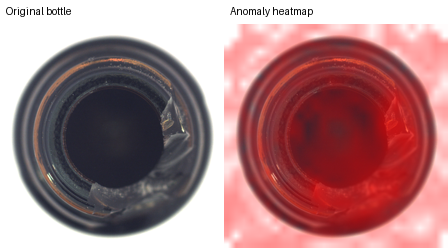

In [ ]:
grid = patch_scores.reshape(1, 1, *grid_size)
heat = F.interpolate(grid, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
heat = (heat - heat.min()) / (heat.max() - heat.min()).clamp_min(1e-8)

original = photo.resize((224, 224))
opacity = Image.fromarray((heat * 180).byte().numpy())
overlay = Image.composite(Image.new("RGB", original.size, "red"), original, opacity)

panel = Image.new("RGB", (448, 248), "white")
panel.paste(original, (0, 24))
panel.paste(overlay, (224, 24))
labels = ImageDraw.Draw(panel)
labels.text((6, 5), "Original bottle", fill="black")
labels.text((230, 5), "Anomaly heatmap", fill="black")
display(panel)

## Part 4 · Calibrate and evaluate

### 14 · Define reusable scoring

Evaluation needs the same calculation for every bottle.

**Read the code.** score_bottle returns two things: the maximum distance and the grid of local distances.

**Check yourself.** This definition finishes silently. Which return value will you use for localization?

In [ ]:
import random
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

if not all(name in globals() for name in ("get_patches", "memory_bank", "chosen", "bottle_dir")):
    raise RuntimeError("Run the memory-bank cell first, then rerun this cell.")


@torch.inference_mode()
def score_bottle(path):
    _, patches, grid_size = get_patches(path)
    scores = torch.cat([
        torch.cdist(chunk, memory_bank).amin(dim=1)
        for chunk in patches.split(128)
    ])
    return scores.max().item(), scores.reshape(*grid_size)

### 15 · Set the decision cutoff

Use 40 other good photos to estimate how unusual a normal bottle can look.

**Read the code.** Subtract chosen from all_good to avoid reusing bank photos. The 95th percentile gives the cutoff.

**Check yourself.** Your run printed 5.196. A bottle must exceed the full-precision cutoff to be flagged.

In [ ]:
all_good = set((bottle_dir / "train" / "good").glob("*.png"))
unused_good = sorted(all_good - set(chosen))
if len(unused_good) < 40:
    raise ValueError(f"Need 40 unused good photos. Found {len(unused_good)}.")

calibration_paths = random.Random(42).sample(unused_good, 40)
normal_scores = [score_bottle(path)[0] for path in calibration_paths]
threshold = float(np.quantile(normal_scores, 0.95, method="higher"))
print(f"Cutoff from 40 good bottles: {threshold:.3f}", flush=True)

Cutoff from 40 good bottles: 5.196


### 16 · Score test photos and align their masks

Each test image has a bottle label. A defect mask also identifies its damaged pixels.

**Read the code.** The loop enlarges raw scores to 224 × 224 and uses nearest-neighbour resizing for binary masks. Good images receive an all-zero mask.

**Check yourself.** Check that there are 83 test scores and that each image contributed a mask.

In [ ]:
test_paths = sorted((bottle_dir / "test").glob("*/*.png"))
image_labels, image_scores = [], []
pixel_labels, pixel_scores = [], []

for path in test_paths:
    defect_type = path.parent.name
    is_defective = defect_type != "good"
    score, grid = score_bottle(path)

    # Enlarge the patch grid to match our 224 × 224 inspection image.
    heat = torch.nn.functional.interpolate(
        grid[None, None], size=(224, 224), mode="bilinear", align_corners=False
    )[0, 0].numpy()

    if is_defective:
        mask_path = bottle_dir / "ground_truth" / defect_type / f"{path.stem}_mask.png"
        if not mask_path.is_file():
            raise FileNotFoundError(f"Missing defect mask: {mask_path}")
        with Image.open(mask_path) as mask:
            mask = mask.convert("L").resize((224, 224), Image.Resampling.NEAREST)
            actual_pixels = np.asarray(mask) > 0
    else:
        actual_pixels = np.zeros((224, 224), dtype=bool)

    image_labels.append(int(is_defective))
    image_scores.append(score)
    pixel_labels.append(actual_pixels.ravel())
    pixel_scores.append(heat.ravel())

if len(set(image_labels)) != 2:
    raise ValueError("Check test/good and the defect folders. Both classes are needed.")


print(len(image_scores), "test scores;", len(pixel_labels), "masks")

### 17 · Count correct and incorrect decisions

A false negative is a damaged bottle accepted as good. ROC-AUC instead measures how well scores rank bottles across cutoffs.

**Read the code.** The confusion matrix uses thresholded labels. roc_auc_score takes continuous scores.

**Check yourself.** Your run accepted 20 good bottles, flagged zero good bottles, detected 58 defects and missed five. Image ROC-AUC was 0.990.

In [ ]:
predictions = (np.asarray(image_scores) > threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(image_labels, predictions, labels=[0, 1]).ravel()

print(f"\nTest bottles: {len(test_paths)}")
print(f"Good correctly accepted: {tn} | Good flagged as defective: {fp}")
print(f"Defects missed: {fn} | Defects correctly detected: {tp}")
print(f"\nImage ROC-AUC: {roc_auc_score(image_labels, image_scores):.3f}")

### 18 · Measure pixel-level localization

A well-ranked heatmap gives defective pixels higher scores than normal pixels.

**Read the code.** Concatenate the masks and corresponding raw scores over all test images.

**Check yourself.** Your pixel ROC-AUC was 0.967 at 224 × 224. This does not say that 96.7% of pixels were classified correctly.

In [ ]:
actual = np.concatenate(pixel_labels)
if actual.any() and not actual.all():
    print(f"Pixel ROC-AUC at 224 × 224: {roc_auc_score(actual, np.concatenate(pixel_scores)):.3f}")

### 19 · Read precision and recall

Precision asks how often a defect warning was correct. Recall asks how many real defects were caught.

**Read the code.** classification_report shows both metrics for each class. Support counts the actual examples.

**Check yourself.** Defective precision was 58/58 and recall was 58/63. Explain how recall can be lower than precision.

In [ ]:
print(classification_report(
    image_labels, predictions, labels=[0, 1],
    target_names=["Normal", "Defective"], zero_division=0
))

## Part 5 · Save, verify and review

### 20 · Prepare the checkpoint

The API needs the bank, threshold, backbone identity and preprocessing settings to reproduce notebook predictions.

**Read the code.** The dictionary also records which normal photos supplied the bank and calibration set.

**Check yourself.** Check that memory_bank and threshold appear in the printed keys.

In [ ]:
from pathlib import Path
import torch
import torchvision

required = ("memory_bank", "threshold", "get_patches", "test_paths",
            "image_labels", "image_scores", "chosen", "calibration_paths", "bottle_dir")
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Rerun the earlier notebook cells. Missing: {', '.join(missing)}")

project_root = Path(bottle_dir).parents[2]
model_path = project_root / "models" / "memory_bank.pt"
model_path.parent.mkdir(parents=True, exist_ok=True)

checkpoint = {
    "memory_bank": memory_bank.detach().cpu(),
    "threshold": float(threshold),
    "weights": str(torchvision.models.ResNet18_Weights.DEFAULT),
    "layers": ["layer2", "layer3"],
    "image_size": [224, 224],
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
    "bank_images": [p.name for p in chosen],
    "calibration_images": [p.name for p in calibration_paths],
}


print(list(checkpoint))

### 21 · Save and reload the detector

Test the serialized bank before replacing a previous checkpoint.

**Read the code.** A temporary file is loaded on CPU, then one score and the threshold are checked before the rename.

**Check yourself.** Look for Reload check passed. Rerunning this cell replaces models/memory_bank.pt after verification.

In [ ]:
temp_path = model_path.with_suffix(".tmp")
torch.save(checkpoint, temp_path)
saved = torch.load(temp_path, map_location="cpu", weights_only=True)

with torch.inference_mode():
    _, patches, _ = get_patches(test_paths[0])
    distances = torch.cat([
        torch.cdist(chunk, saved["memory_bank"]).amin(dim=1)
        for chunk in patches.split(128)
    ])
    reloaded_score = distances.max().item()

if abs(reloaded_score - image_scores[0]) > 1e-4 or saved["threshold"] != threshold:
    raise RuntimeError("Reload check failed. The saved values need inspection.")

temp_path.replace(model_path)
print("Saved:", model_path.relative_to(project_root))
print("Reload check passed for:", test_paths[0].name)

### 22 · Review missed defects

Inspect failures to learn which kinds of defect require further study.

**Read the code.** Print the defect folder and score whenever a defective test image fell at or below the cutoff.

**Check yourself.** Your run missed one small break and four contaminated bottles. What would these five cases look like in the app?

In [ ]:
print("\nMissed defects:")
for path, label, score in zip(test_paths, image_labels, image_scores):
    if label == 1 and score <= threshold:
        print(f"{path.parent.name}/{path.name}   score={score:.3f}")

## Part 6 · Connect the notebook to the app

The application lives in separate files. FastAPI loads models/memory_bank.pt and uses the same ResNet18 weights and transforms. React sends a bottle photo to POST /predict and displays the returned score, cutoff, prediction and relative heatmap. For the previously inspected broken 003.png, the local app showed 5.817 against 5.196.

**Revise aloud:** Which 8 photos supply the bank? Why reserve 40 different photos for calibration? How can a normal bottle still have red regions? Why do the image and pixel ROC-AUC answer different questions?